Imports, podem alterar conforme necessário

In [ ]:
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress, stats
import plotly.express as px
from sklearn.decomposition import PCA
from sklearn.impute import KNNImputer
from sklearn.preprocessing import MinMaxScaler

In [ ]:
def remove_outliers_zscore(df, coluna, limt):
    # Calcula o Z-score para a coluna especificada
    z_scores = np.abs(stats.zscore(df[coluna]))

    # Remove os outliers
    df_filtrado = df[z_scores < limt]

    return df_filtrado
def normaliza_z(df, coluna):
    df_norm = df.copy()

    # Calcula a média e o desvio padrão da coluna específica
    media = df_norm[coluna].mean()
    desvio_padrao = df_norm[coluna].std()

    # Aplica a normalização Z para a coluna específica
    df_norm[coluna] = (df_norm[coluna] - media) / desvio_padrao

    return df_norm

#### Lendo base de dados e removendo valores aleatoriamente **executar SEM ALTERAR**

In [ ]:
#Carregando base de dados
penguins = sns.load_dataset('penguins')
penguins2=penguins.dropna()

np.random.seed(42)  #Definindo seed do random para replicabilidade

#Removendo valores
removidos = set()
porcentagem = 0.30 #Porcentagem (0~1) das células a serem removidas
qtdCelulas = len(penguins)*(len(penguins.columns)) #Quantidade de células na base de dados, ignorando a última coluna

for i in range(int(np.ceil(porcentagem*qtdCelulas))):
  linha = np.random.randint(0, len(penguins))
  coluna = np.random.randint(0, len(penguins.columns))
  while (linha, coluna) in removidos:
    linha = np.random.randint(0, len(penguins))
    coluna = np.random.randint(0, len(penguins.columns))

  penguins.iloc[linha, coluna] = np.nan
  removidos.add((linha,coluna))

penguins.info()
print("\n\nForam removidas ",str(len(removidos)), "células das ",str(qtdCelulas))
del removidos


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            232 non-null    object 
 1   island             241 non-null    object 
 2   bill_length_mm     233 non-null    float64
 3   bill_depth_mm      244 non-null    float64
 4   flipper_length_mm  247 non-null    float64
 5   body_mass_g        240 non-null    float64
 6   sex                235 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


Foram removidas  723 células das  2408


# **Podem modificar daqui para baixo para fazer a imputação de valores**

---
Observando o DataFrame

In [ ]:
penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,NaN,18.7,NaN,3750.0,Male
1,NaN,NaN,39.5,17.4,186.0,NaN,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,NaN,NaN,NaN,NaN,NaN,NaN
4,Adelie,NaN,NaN,19.3,193.0,3450.0,NaN


In [ ]:
penguins2

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male
...,...,...,...,...,...,...,...
338,Gentoo,Biscoe,47.2,13.7,214.0,4925.0,Female
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,Female
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,Male
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,Female


---
## Fazendo o pairplot para analisar a correlação entre cada atributo, separados por espécie

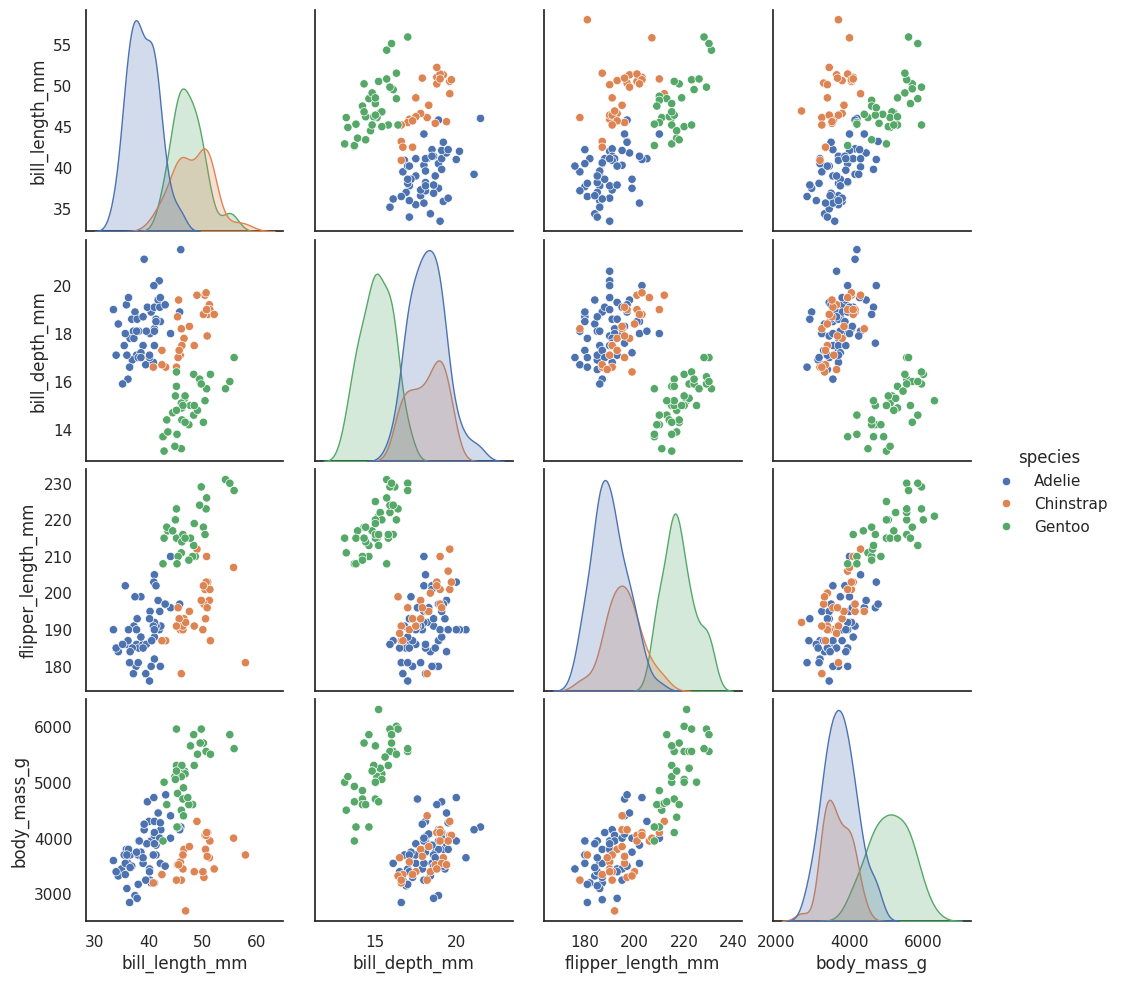

In [ ]:
sns.pairplot(penguins, hue='species')

---
# Plotando um bloxplot comparando a massa dos penguins com a espécie,
Podemos ver que os penguins da espécie "Gentoo" tendem a ter uma massa maior.


<Axes: xlabel='species', ylabel='body_mass_g'>

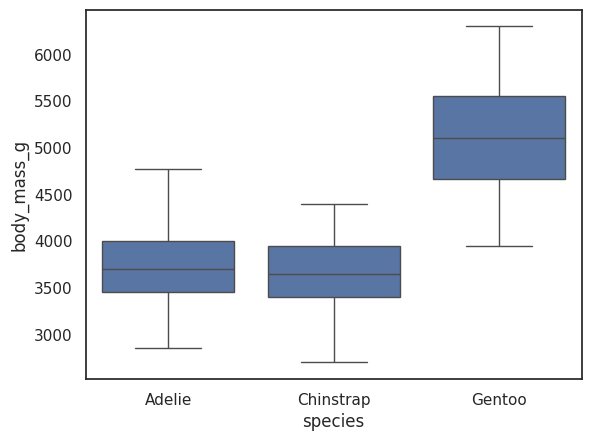

In [ ]:
sns.boxplot(data=penguins, x="species", y ="body_mass_g",showfliers=True)

---
# Plotando um bloxplot comparando o tamanho do bico com a espécie,
 Quando plotamos o boxplot comparando a espécie com o ctamanho da curvatura, notamos que os penguins "Chinstrap" possuem bicos mais alongados.

<Axes: xlabel='species', ylabel='bill_length_mm'>

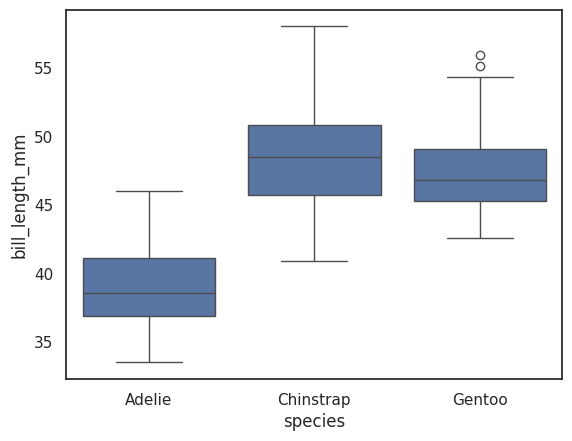

In [ ]:
sns.boxplot(data=penguins, x="species", y ="bill_length_mm",showfliers=True)#Existe outliers


---
#Plotando um bloxplot comparando a largura do bico com a espécie,
Quando plotamos o boxplot comparando a espécie com o tamanho do bico, notamos que os penguins "Chinstrap" e "Adelie" possuem bicos maiores.

<Axes: xlabel='species', ylabel='bill_depth_mm'>

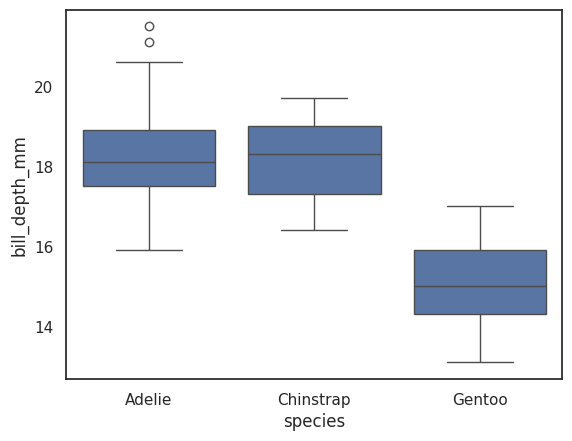

In [ ]:
sns.boxplot(data=penguins, x="species", y ="bill_depth_mm",showfliers=True) #Existe outliers

---
#Plotando um bloxplot comparando o tamanho da nadadeira com a espécie,
Quando plotamos o boxplot comparando a espécie com o tamanho da nadadeira, notamos que os penguins "Gentoo" possuem nadadeiras maiores.

<Axes: xlabel='species', ylabel='flipper_length_mm'>

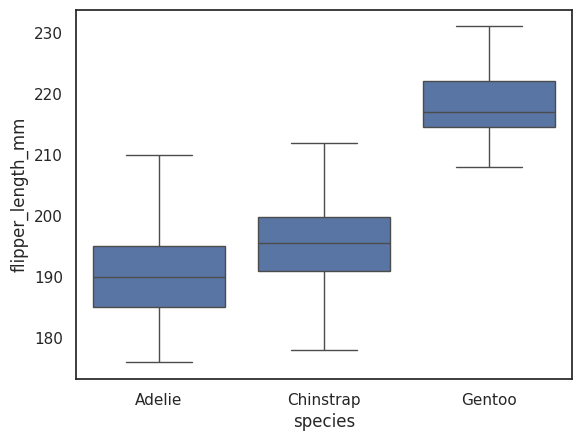

In [ ]:
sns.boxplot(data=penguins,x="species",y="flipper_length_mm")

---
## Removendo os outliers

<ipython-input-75-248e65d3fffc>:3: DeprecationWarning:

Please use `zscore` from the `scipy.stats` namespace, the `scipy.stats.stats` namespace is deprecated.



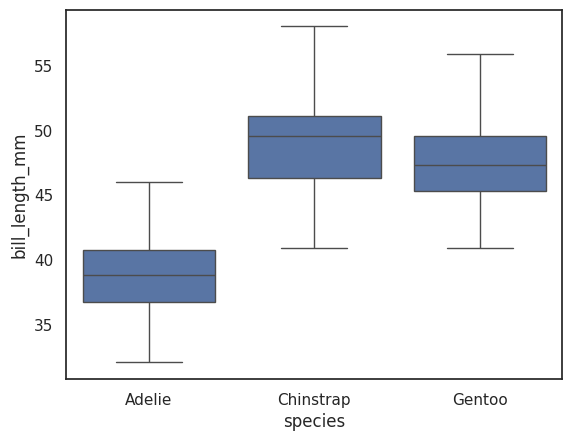

In [ ]:
# Aplica a função remove_outliers na coluna 'bill_length_mm'
penguins2=remove_outliers_zscore(penguins2,"bill_length_mm",2.6)
sns.boxplot(data=penguins2,x="species",y="bill_length_mm")
plt.show()

<ipython-input-75-248e65d3fffc>:3: DeprecationWarning:

Please use `zscore` from the `scipy.stats` namespace, the `scipy.stats.stats` namespace is deprecated.



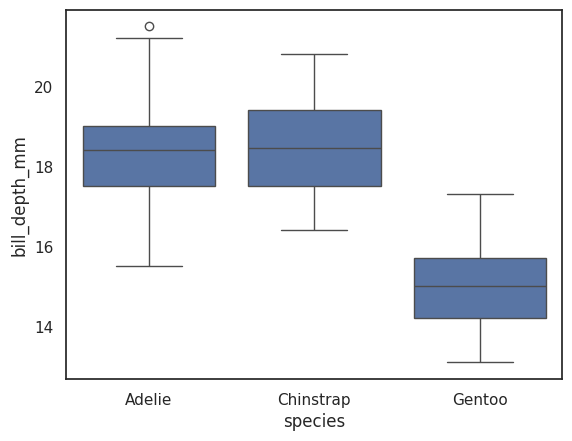

In [ ]:
penguins2=remove_outliers_zscore(penguins2,"bill_depth_mm",3)
sns.boxplot(data=penguins2,x="species",y="bill_depth_mm")
plt.show()

---

In [ ]:
# Vendo quantos nomes não nulos de espécies existem
print(penguins.value_counts('species').sum())
print(penguins.info())
print(len(penguins))

232
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            232 non-null    object 
 1   island             241 non-null    object 
 2   bill_length_mm     233 non-null    float64
 3   bill_depth_mm      244 non-null    float64
 4   flipper_length_mm  247 non-null    float64
 5   body_mass_g        240 non-null    float64
 6   sex                235 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB
None
344


---
#Nesta parte substituímos os valores faltantes da coluna espécie pelo valor da coluna acima, uma vez que os valores estão organizados em ordem arfabética

In [ ]:
for pos, species in enumerate(penguins['species']):
    # Verificar se o valor atual é nulo
    if pd.isnull(species):
        # Pegar o valor da linha anterior
        troca = penguins.loc[pos - 1, 'species']
        # Substituir o valor nulo pelo valor da linha anterior

        penguins.loc[pos, 'species'] = troca
penguins


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,NaN,18.7,NaN,3750.0,Male
1,Adelie,NaN,39.5,17.4,186.0,NaN,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,NaN,NaN,NaN,NaN,NaN,NaN
4,Adelie,NaN,NaN,19.3,193.0,3450.0,NaN
...,...,...,...,...,...,...,...
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN
340,Gentoo,NaN,46.8,14.3,215.0,NaN,NaN
341,Gentoo,Biscoe,NaN,NaN,NaN,5750.0,NaN
342,Gentoo,Biscoe,45.2,14.8,NaN,5200.0,Female


In [ ]:
# Vendo se os valores nulos foram todos excluídos
penguins.value_counts('species').sum()

344

In [ ]:
# Vendo os valores não nulos na coluna island
penguins['island'].value_counts().sum()

241

---
#Aqui substituímos os valores faltantes da coluna "island" pela ilha de cada espécie de pinguim

primerio vamos observar se há alguma diferença muito grande entre as variaveis numéricas e as ilhas

In [ ]:
# Agrupando a especie e a ilha
print("Média da massa para todas as espécies e ilhas")
print(penguins2.groupby(['species', 'island'])['body_mass_g'].mean())
print()
print("Média do tamanho da nadadeira para todas as espécies e ilhas")
print(penguins2.groupby(['species', 'island'])['flipper_length_mm'].mean())
print()
print("Média do tamanho do bico para todas as espécies e ilhas")
print(penguins2.groupby(['species', 'island'])['bill_length_mm'].mean())
print()
print("Média da largura do bico para todas as espécies e ilhas")
print(penguins2.groupby(['species', 'island'])['bill_depth_mm'].mean())



Média da massa para todas as espécies e ilhas
species    island   
Adelie     Biscoe       3709.659091
           Dream        3701.363636
           Torgersen    3708.510638
Chinstrap  Dream        3733.088235
Gentoo     Biscoe       5092.436975
Name: body_mass_g, dtype: float64

Média do tamanho da nadadeira para todas as espécies e ilhas
species    island   
Adelie     Biscoe       188.795455
           Dream        189.927273
           Torgersen    191.531915
Chinstrap  Dream        195.823529
Gentoo     Biscoe       217.235294
Name: flipper_length_mm, dtype: float64

Média do tamanho do bico para todas as espécies e ilhas
species    island   
Adelie     Biscoe       38.975000
           Dream        38.520000
           Torgersen    39.038298
Chinstrap  Dream        48.833824
Gentoo     Biscoe       47.568067
Name: bill_length_mm, dtype: float64

Média da largura do bico para todas as espécies e ilhas
species    island   
Adelie     Biscoe       18.370455
           Dream        

Com esses resultados é possivel concluir que a ilha não diferencia fortemente as características físicas dos penguins, somente a espécie "Gentoo" que tende a ser maior.


In [ ]:
# Portanto dessa maneira vamos substituir os valores nulos pelo seu antecessor,
for pos, ilha in enumerate(penguins['island']):
  if pd.isnull(ilha):
    troca = penguins['island'][pos-1]
    penguins['island'][pos] = troca
penguins

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,NaN,18.7,NaN,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,NaN,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,NaN,19.3,193.0,3450.0,NaN
...,...,...,...,...,...,...,...
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN
340,Gentoo,Biscoe,46.8,14.3,215.0,NaN,NaN
341,Gentoo,Biscoe,NaN,NaN,NaN,5750.0,NaN
342,Gentoo,Biscoe,45.2,14.8,NaN,5200.0,Female


In [ ]:
# Vendo se todos os valores nulos foram substituídos
penguins['island'].value_counts().sum()

344

---
# Observando o dataframe em 3 dimensões sem normalizar


In [ ]:
fig = px.scatter_3d(penguins, x='flipper_length_mm', y='body_mass_g', z='bill_depth_mm', color='species',title="Penquins")
fig.show()

O mesmo grádico após a normalização usando o z-score


In [ ]:
penguins_norm_z=penguins2.copy()
penguins_norm_z=normaliza_z(penguins_norm_z,"flipper_length_mm")
penguins_norm_z=normaliza_z(penguins_norm_z,"body_mass_g")
penguins_norm_z=normaliza_z(penguins_norm_z,"bill_depth_mm")
fig = px.scatter_3d(penguins_norm_z, x='flipper_length_mm', y='body_mass_g', z='bill_depth_mm', color='species',title="Penguins")
fig.show()

---
# Nesta seção vamos estimar os valores de "bill_length_mm", "bill_depth_mm", "flipper_length_mm"e "body_mass_g"
para isso devemos primeiros ver as relações entre as variáveis

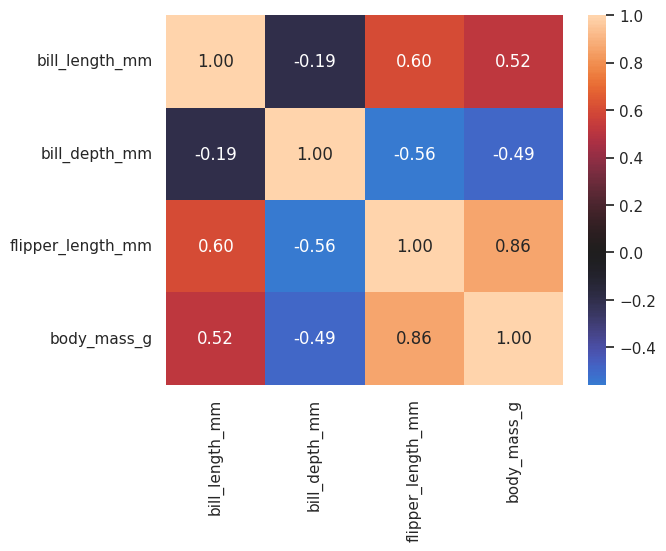

In [ ]:
correlacao=sns.heatmap(penguins.corr(numeric_only=True), fmt=".2f", annot=True, center=0.0) #CORRELAÇÃO DENTRO DE UM MAPA DE CALOR

---
# Gráfico entre o tamanho da nadadeira e o massa do pinguim

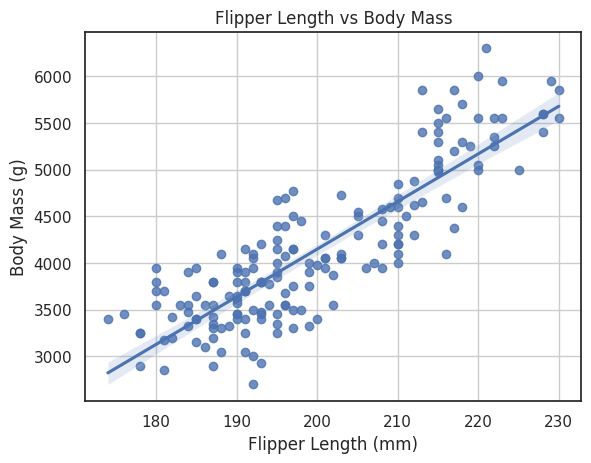

In [ ]:
sns.regplot(data=penguins,x="flipper_length_mm", y="body_mass_g")
sns.set_theme(style="white")
plt.xlabel('Flipper Length (mm)')
plt.ylabel('Body Mass (g)')
plt.title('Flipper Length vs Body Mass')
plt.grid()

In [ ]:
def eq_linear(x):
  y=a*x+b
  return y
def calcula_media_nadadeira(especie, df):
    # Filtra o DataFrame para a espécie especificada e remove os valores NaN da coluna 'flipper_length_mm'
    especie_df = df[df['species'] == especie]['flipper_length_mm'].dropna()

    # Calcula a média da coluna filtrada
    media = especie_df.mean()

    return media

---
# Determinando a equação linear que relaciona o comprimento (y) da nadadeira (flipper_length) e a massa corporal x (body_mass)

In [ ]:
#Definindo as valores de A e B da equação linear
a = linregress(x = penguins2.body_mass_g, y = penguins2.flipper_length_mm).slope
b = linregress(x = penguins2.body_mass_g, y = penguins2.flipper_length_mm).intercept
print(f"Para uma massa corporal X o tamanho da nadadeira Y pode ser descrito pela formula: Y={round(a,4)}x+{round(b)}")

Para uma massa corporal X o tamanho da nadadeira Y pode ser descrito pela formula: Y=0.0152x+137


---
#Utilizando O KNN(K-Nearest Neighbors) para obter uma métrica melhor

In [ ]:
penguins.replace("Male",1,inplace=True) #Substituindo "Male" por 1
penguins.replace("Female",0,inplace=True) #"Female" por 0

In [ ]:
# Primeiro, selecionaremos as linhas que possuem mais de 3 valores numéricos nulos, pois existe uma grande possibilidade desses valores serem colocados em locais indesejados
# Essas lihas serão removidas do df final
# Criando um df com para analisar apenas as coluans numéricas
colunas_numericas = list(penguins.columns)
colunas_numericas.remove('species')
colunas_numericas.remove('island')
colunas_numericas

['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex']

In [ ]:
# Visualizando o df com apenas coluanas numéricas
penguins_numerico = penguins[colunas_numericas]
penguins_numerico

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,NaN,18.7,NaN,3750.0,1.0
1,39.5,17.4,186.0,NaN,0.0
2,40.3,18.0,195.0,3250.0,0.0
3,NaN,NaN,NaN,NaN,NaN
4,NaN,19.3,193.0,3450.0,NaN
...,...,...,...,...,...
339,NaN,NaN,NaN,NaN,NaN
340,46.8,14.3,215.0,NaN,NaN
341,NaN,NaN,NaN,5750.0,NaN
342,45.2,14.8,NaN,5200.0,0.0


In [ ]:
# Filtrando as linhas que possuem 3 ou mais valores nulos e guardando o filtro para, no final, excluirmos estas linhas
filtro = penguins_numerico.isna().sum(axis=1) >= 4
penguins[filtro]

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
38,Adelie,Dream,NaN,19.3,NaN,NaN,NaN
50,Adelie,Biscoe,NaN,NaN,NaN,NaN,0.0
252,Gentoo,Biscoe,NaN,NaN,NaN,NaN,0.0
290,Gentoo,Biscoe,NaN,15.0,NaN,NaN,NaN
292,Gentoo,Biscoe,NaN,15.6,NaN,NaN,NaN
317,Gentoo,Biscoe,NaN,NaN,NaN,NaN,0.0
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN
341,Gentoo,Biscoe,NaN,NaN,NaN,5750.0,NaN


In [ ]:
# Criação do MinMaxScaler
scaler = MinMaxScaler()
# Aprendendo os valores de mínimo e máximo
scaler.fit(penguins[colunas_numericas])
# Modificando os dados
penguins_normalizado = scaler.transform(penguins[colunas_numericas])
# Visualizando as modificações
penguins_normalizado[:5]

array([[       nan, 0.66666667,        nan, 0.29166667, 1.        ],
       [0.24489796, 0.51190476, 0.21052632,        nan, 0.        ],
       [0.27755102, 0.58333333, 0.36842105, 0.15277778, 0.        ],
       [       nan,        nan,        nan,        nan,        nan],
       [       nan, 0.73809524, 0.33333333, 0.20833333,        nan]])

In [ ]:
# Criando um df com os valores normalizados
df_penguins_normalizado = pd.DataFrame(penguins_normalizado, columns=colunas_numericas)
df_penguins_normalizado

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,NaN,0.666667,NaN,0.291667,1.0
1,0.244898,0.511905,0.210526,NaN,0.0
2,0.277551,0.583333,0.368421,0.152778,0.0
3,NaN,NaN,NaN,NaN,NaN
4,NaN,0.738095,0.333333,0.208333,NaN
...,...,...,...,...,...
339,NaN,NaN,NaN,NaN,NaN
340,0.542857,0.142857,0.719298,NaN,NaN
341,NaN,NaN,NaN,0.847222,NaN
342,0.477551,0.202381,NaN,0.694444,0.0


In [ ]:
# Adicionando as colunas espécie e ilha ao df
df_penguins_normalizado['species'] = penguins['species']
df_penguins_normalizado['island'] = penguins['island']
df_penguins_normalizado

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,species,island
0,NaN,0.666667,NaN,0.291667,1.0,Adelie,Torgersen
1,0.244898,0.511905,0.210526,NaN,0.0,Adelie,Torgersen
2,0.277551,0.583333,0.368421,0.152778,0.0,Adelie,Torgersen
3,NaN,NaN,NaN,NaN,NaN,Adelie,Torgersen
4,NaN,0.738095,0.333333,0.208333,NaN,Adelie,Torgersen
...,...,...,...,...,...,...,...
339,NaN,NaN,NaN,NaN,NaN,Gentoo,Biscoe
340,0.542857,0.142857,0.719298,NaN,NaN,Gentoo,Biscoe
341,NaN,NaN,NaN,0.847222,NaN,Gentoo,Biscoe
342,0.477551,0.202381,NaN,0.694444,0.0,Gentoo,Biscoe


In [ ]:
# Utilizando oficialmente o KNNImputer
# Escolhendo o número de vizinhos
imputer = KNNImputer(n_neighbors=5, weights='distance', copy=True)

# Escolhendo os valores ideais
imputer.fit(df_penguins_normalizado[colunas_numericas])

#Alterando os nans
df_penguins_normalizado[colunas_numericas] = imputer.transform(df_penguins_normalizado[colunas_numericas])

df_penguins_normalizado

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,species,island
0,0.358040,0.666667,0.378401,0.291667,1.000000,Adelie,Torgersen
1,0.244898,0.511905,0.210526,0.201389,0.000000,Adelie,Torgersen
2,0.277551,0.583333,0.368421,0.152778,0.000000,Adelie,Torgersen
3,0.416169,0.483119,0.466297,0.409317,0.523404,Adelie,Torgersen
4,0.061225,0.738095,0.333333,0.208333,0.302521,Adelie,Torgersen
...,...,...,...,...,...,...,...
339,0.416169,0.483119,0.466297,0.409317,0.523404,Gentoo,Biscoe
340,0.542857,0.142857,0.719298,0.638889,0.000000,Gentoo,Biscoe
341,0.657143,0.230952,0.745614,0.847222,1.000000,Gentoo,Biscoe
342,0.477551,0.202381,0.692982,0.694444,0.000000,Gentoo,Biscoe


In [ ]:
# Voltando os valores normalizados ao normal
penguins_final = scaler.inverse_transform(df_penguins_normalizado[colunas_numericas])
penguins_final[:5]

array([[4.22719769e+01, 1.87000000e+01, 1.95568870e+02, 3.75000000e+03,
        1.00000000e+00],
       [3.95000000e+01, 1.74000000e+01, 1.86000000e+02, 3.42500000e+03,
        0.00000000e+00],
       [4.03000000e+01, 1.80000000e+01, 1.95000000e+02, 3.25000000e+03,
        0.00000000e+00],
       [4.36961373e+01, 1.71581967e+01, 2.00578947e+02, 4.17354167e+03,
        5.23404255e-01],
       [3.50000108e+01, 1.93000000e+01, 1.93000000e+02, 3.45000000e+03,
        3.02520732e-01]])

In [ ]:
# Criando o df final com os valores numéricos nulos preenchidos
df_penguins_final = pd.DataFrame(penguins_final, columns=colunas_numericas)
df_penguins_final['species'] = df_penguins_normalizado['species']
df_penguins_final['island'] = df_penguins_normalizado['island']

df_penguins_final

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,species,island
0,42.271977,18.700000,195.568870,3750.000000,1.000000,Adelie,Torgersen
1,39.500000,17.400000,186.000000,3425.000000,0.000000,Adelie,Torgersen
2,40.300000,18.000000,195.000000,3250.000000,0.000000,Adelie,Torgersen
3,43.696137,17.158197,200.578947,4173.541667,0.523404,Adelie,Torgersen
4,35.000011,19.300000,193.000000,3450.000000,0.302521,Adelie,Torgersen
...,...,...,...,...,...,...,...
339,43.696137,17.158197,200.578947,4173.541667,0.523404,Gentoo,Biscoe
340,46.800000,14.300000,215.000000,5000.000000,0.000000,Gentoo,Biscoe
341,49.600000,15.040000,216.500000,5750.000000,1.000000,Gentoo,Biscoe
342,45.200000,14.800000,213.500000,5200.000000,0.000000,Gentoo,Biscoe


In [ ]:
# Após substituir os valores numéricos nulos, vamos remover aquelas linhas que possuiam 3 ou mais valores nulos
remover = penguins[filtro].index
df_penguins_final.drop(remover, axis=0, inplace=True)
df_penguins_final

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,species,island
0,42.271977,18.700000,195.56887,3750.000000,1.000000,Adelie,Torgersen
1,39.500000,17.400000,186.00000,3425.000000,0.000000,Adelie,Torgersen
2,40.300000,18.000000,195.00000,3250.000000,0.000000,Adelie,Torgersen
4,35.000011,19.300000,193.00000,3450.000000,0.302521,Adelie,Torgersen
5,43.900000,20.600000,190.00000,3650.000000,1.000000,Adelie,Torgersen
...,...,...,...,...,...,...,...
337,48.800000,16.200000,222.00000,5429.269495,1.000000,Gentoo,Biscoe
338,40.900000,13.700000,199.00000,4925.000000,0.000000,Gentoo,Biscoe
340,46.800000,14.300000,215.00000,5000.000000,0.000000,Gentoo,Biscoe
342,45.200000,14.800000,213.50000,5200.000000,0.000000,Gentoo,Biscoe


In [ ]:
# Resetando o index para o padrão
df_penguins_final = df_penguins_final.reset_index()
df_penguins_final

,index,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,species,island
0,0,42.271977,18.700000,195.56887,3750.000000,1.000000,Adelie,Torgersen
1,1,39.500000,17.400000,186.00000,3425.000000,0.000000,Adelie,Torgersen
2,2,40.300000,18.000000,195.00000,3250.000000,0.000000,Adelie,Torgersen
3,4,35.000011,19.300000,193.00000,3450.000000,0.302521,Adelie,Torgersen
4,5,43.900000,20.600000,190.00000,3650.000000,1.000000,Adelie,Torgersen
...,...,...,...,...,...,...,...,...
330,337,48.800000,16.200000,222.00000,5429.269495,1.000000,Gentoo,Biscoe
331,338,40.900000,13.700000,199.00000,4925.000000,0.000000,Gentoo,Biscoe
332,340,46.800000,14.300000,215.00000,5000.000000,0.000000,Gentoo,Biscoe
333,342,45.200000,14.800000,213.50000,5200.000000,0.000000,Gentoo,Biscoe


In [ ]:
# Removendo a coluna 'index' que ficou sobrando
df_penguins_final = df_penguins_final.drop('index', axis=1)
df_penguins_final

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,species,island
0,42.271977,18.700000,195.56887,3750.000000,1.000000,Adelie,Torgersen
1,39.500000,17.400000,186.00000,3425.000000,0.000000,Adelie,Torgersen
2,40.300000,18.000000,195.00000,3250.000000,0.000000,Adelie,Torgersen
3,35.000011,19.300000,193.00000,3450.000000,0.302521,Adelie,Torgersen
4,43.900000,20.600000,190.00000,3650.000000,1.000000,Adelie,Torgersen
...,...,...,...,...,...,...,...
330,48.800000,16.200000,222.00000,5429.269495,1.000000,Gentoo,Biscoe
331,40.900000,13.700000,199.00000,4925.000000,0.000000,Gentoo,Biscoe
332,46.800000,14.300000,215.00000,5000.000000,0.000000,Gentoo,Biscoe
333,45.200000,14.800000,213.50000,5200.000000,0.000000,Gentoo,Biscoe


In [ ]:
df_penguins_final.head(15)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,species,island
0,42.271977,18.700000,195.568870,3750.000000,1.000000e+00,Adelie,Torgersen
1,39.500000,17.400000,186.000000,3425.000000,0.000000e+00,Adelie,Torgersen
2,40.300000,18.000000,195.000000,3250.000000,0.000000e+00,Adelie,Torgersen
3,35.000011,19.300000,193.000000,3450.000000,3.025207e-01,Adelie,Torgersen
4,43.900000,20.600000,190.000000,3650.000000,1.000000e+00,Adelie,Torgersen
5,37.533333,17.800000,181.000000,3366.666667,0.000000e+00,Adelie,Torgersen
6,39.200000,18.600000,195.000000,4675.000000,1.000000e+00,Adelie,Torgersen
7,34.100000,18.100000,193.000000,3475.000000,0.000000e+00,Adelie,Torgersen
8,42.000000,20.200000,190.000000,3905.998884,6.964941e-07,Adelie,Torgersen
9,37.800000,17.100000,186.000000,3728.542510,2.713178e-01,Adelie,Torgersen


Agora precisamos arredondar os valores de "Sex" para 0 e 1 e voltar a varivel para categorica

In [ ]:
# Trocando os valores continuos por zero e um conforme mais se aproximam
value=df_penguins_final["sex"]
value=round(value)
df_penguins_final["sex"]=value
df_penguins_final

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,species,island
0,42.271977,18.700000,195.56887,3750.000000,1.0,Adelie,Torgersen
1,39.500000,17.400000,186.00000,3425.000000,0.0,Adelie,Torgersen
2,40.300000,18.000000,195.00000,3250.000000,0.0,Adelie,Torgersen
3,35.000011,19.300000,193.00000,3450.000000,0.0,Adelie,Torgersen
4,43.900000,20.600000,190.00000,3650.000000,1.0,Adelie,Torgersen
...,...,...,...,...,...,...,...
330,48.800000,16.200000,222.00000,5429.269495,1.0,Gentoo,Biscoe
331,40.900000,13.700000,199.00000,4925.000000,0.0,Gentoo,Biscoe
332,46.800000,14.300000,215.00000,5000.000000,0.0,Gentoo,Biscoe
333,45.200000,14.800000,213.50000,5200.000000,0.0,Gentoo,Biscoe


In [ ]:
#Voltando ao valores originais
df_penguins_final.replace(1,"Male",inplace=True)
df_penguins_final.replace(0,"Female",inplace=True)
df_penguins_final

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,species,island
0,42.271977,18.700000,195.56887,3750.000000,Male,Adelie,Torgersen
1,39.500000,17.400000,186.00000,3425.000000,Female,Adelie,Torgersen
2,40.300000,18.000000,195.00000,3250.000000,Female,Adelie,Torgersen
3,35.000011,19.300000,193.00000,3450.000000,Female,Adelie,Torgersen
4,43.900000,20.600000,190.00000,3650.000000,Male,Adelie,Torgersen
...,...,...,...,...,...,...,...
330,48.800000,16.200000,222.00000,5429.269495,Male,Gentoo,Biscoe
331,40.900000,13.700000,199.00000,4925.000000,Female,Gentoo,Biscoe
332,46.800000,14.300000,215.00000,5000.000000,Female,Gentoo,Biscoe
333,45.200000,14.800000,213.50000,5200.000000,Female,Gentoo,Biscoe


In [ ]:
Final_penguins=df_penguins_final.round(4)
Final_penguins

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,species,island
0,42.272,18.7000,195.5689,3750.0000,Male,Adelie,Torgersen
1,39.500,17.4000,186.0000,3425.0000,Female,Adelie,Torgersen
2,40.300,18.0000,195.0000,3250.0000,Female,Adelie,Torgersen
3,35.000,19.3000,193.0000,3450.0000,Female,Adelie,Torgersen
4,43.900,20.6000,190.0000,3650.0000,Male,Adelie,Torgersen
...,...,...,...,...,...,...,...
330,48.800,16.2000,222.0000,5429.2695,Male,Gentoo,Biscoe
331,40.900,13.7000,199.0000,4925.0000,Female,Gentoo,Biscoe
332,46.800,14.3000,215.0000,5000.0000,Female,Gentoo,Biscoe
333,45.200,14.8000,213.5000,5200.0000,Female,Gentoo,Biscoe


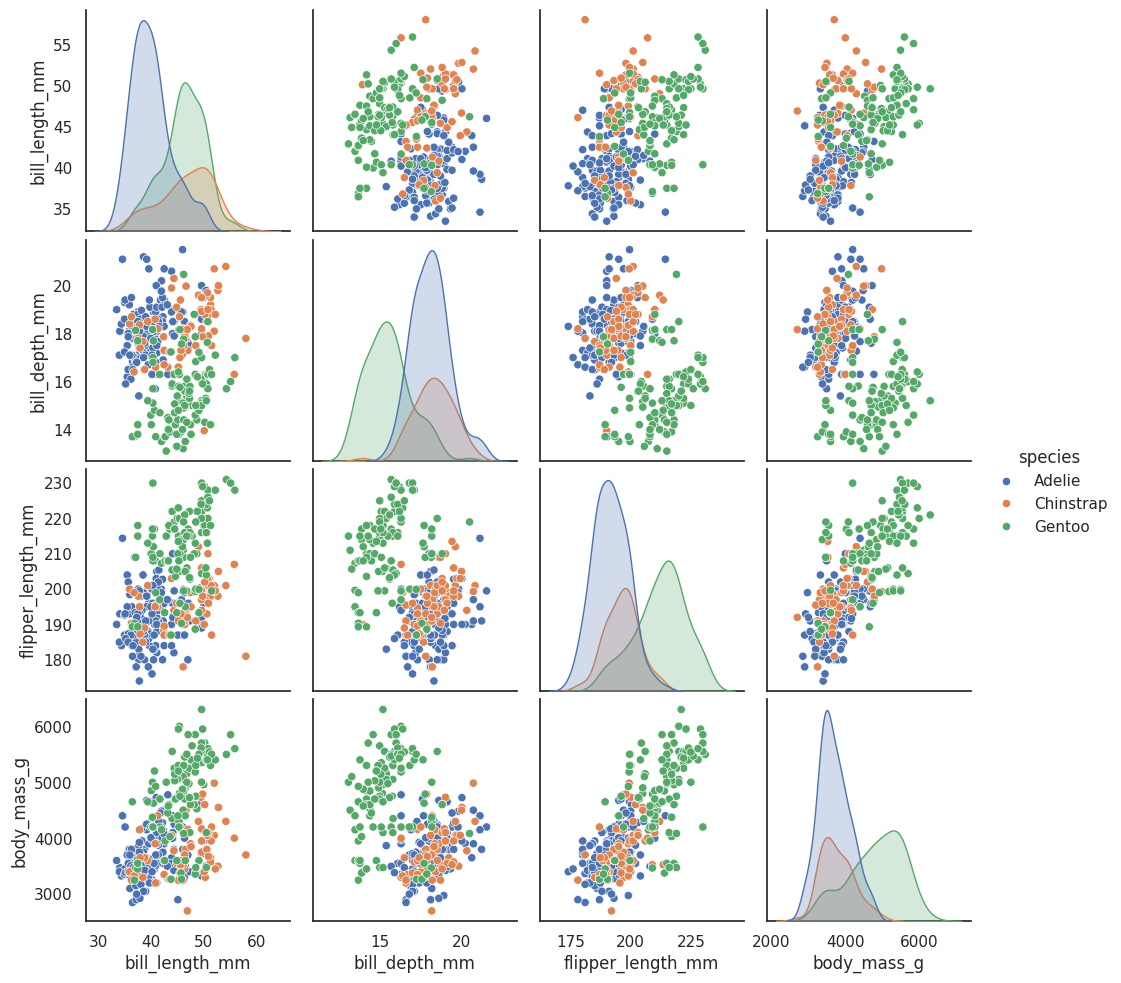

In [ ]:
sns.pairplot(df_penguins_final, hue='species')

---
#Gráfico 3d após o tratamento normalizado

In [ ]:
penguins_final_norm_z=df_penguins_final.copy()
penguins_final_norm_z=normaliza_z(penguins_final_norm_z,"flipper_length_mm")
penguins_final_norm_z=normaliza_z(penguins_final_norm_z,"body_mass_g")
penguins_final_norm_z=normaliza_z(penguins_final_norm_z,"bill_depth_mm")
fig = px.scatter_3d(penguins_final_norm_z, x='flipper_length_mm', y='body_mass_g', z='bill_depth_mm', color='species',title="Penguins")
fig.show()